## Prueba - Análisis estadístico con Python

### Análisis de riesgo cardiovascular


In [152]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix,classification_report
from imblearn.over_sampling import SMOTE

1. Carga los datos y explóralos. Elimina los datos nulos o incorrectos

In [153]:
df=pd.read_csv('cardio.csv')
df.head()

,sex,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,M,39,4.0,No,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,F,46,2.0,No,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,M,48,1.0,Yes,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,F,61,3.0,Yes,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,F,46,3.0,Yes,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [154]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sex              4238 non-null   object 
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   object 
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(5), object(2)
memory usage: 529.9+ KB


In [155]:
df.duplicated().sum()

np.int64(0)

In [156]:
null_counts= df.isnull().sum()
columns_con_nulls= null_counts[null_counts > 0]
columns_con_nulls

education     105
cigsPerDay     29
BPMeds         53
totChol        50
BMI            19
heartRate       1
glucose       388
dtype: int64

In [157]:
df[columns_con_nulls.index].describe()

,education,cigsPerDay,BPMeds,totChol,BMI,heartRate,glucose
count,4133.000000,4209.000000,4185.000000,4188.000000,4219.000000,4237.000000,3850.000000
mean,1.978950,9.003089,0.029630,236.721585,25.802008,75.878924,81.966753
std,1.019791,11.920094,0.169584,44.590334,4.080111,12.026596,23.959998
min,1.000000,0.000000,0.000000,107.000000,15.540000,44.000000,40.000000
25%,1.000000,0.000000,0.000000,206.000000,23.070000,68.000000,71.000000
50%,2.000000,0.000000,0.000000,234.000000,25.400000,75.000000,78.000000
75%,3.000000,20.000000,0.000000,263.000000,28.040000,83.000000,87.000000
max,4.000000,70.000000,1.000000,696.000000,56.800000,143.000000,394.000000


In [158]:
for col in columns_con_nulls.index:
    df[col] = df[col].fillna(df[col].median())

In [159]:
df[columns_con_nulls.index].describe()

,education,cigsPerDay,BPMeds,totChol,BMI,heartRate,glucose
count,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000
mean,1.979471,8.941482,0.029259,236.689476,25.800205,75.878716,81.603587
std,1.007081,11.902399,0.168552,44.327427,4.071041,12.025185,22.865246
min,1.000000,0.000000,0.000000,107.000000,15.540000,44.000000,40.000000
25%,1.000000,0.000000,0.000000,206.000000,23.080000,68.000000,72.000000
50%,2.000000,0.000000,0.000000,234.000000,25.400000,75.000000,78.000000
75%,3.000000,20.000000,0.000000,262.000000,28.037500,83.000000,85.000000
max,4.000000,70.000000,1.000000,696.000000,56.800000,143.000000,394.000000


In [160]:
# En lugar de eliminar los registros con valores nulos, se optó por imputarlos utilizando
# la mediana con el fin de conservar la mayor cantidad de información del dataset. Esta
# decisión se basó en el análisis descriptivo, donde la mayoría de las variables presentan
# una diferencia reducida entre la media y la mediana. Además, la mediana es una medida
# robusta frente a valores atípicos, por lo que su uso resulta adecuado considerando que
# posteriormente se realizará un análisis y tratamiento de dichos valores. En particular,
# la variable 'glucose', que presentaba la mayor cantidad de valores nulos, tampoco mostró
# diferencias importantes entre sus medidas de tendencia central.

2. Escoge tres variables cuantitativas y realiza un análisis descriptivo de ellas,
utilizando indicadores y gráficos. ¿Cuaĺ presenta mayor dispersión?


In [161]:
df.columns

Index(['sex', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD'],
      dtype='object')

In [162]:
df_filtrado=df[['totChol','sysBP','BMI']]
cv = df_filtrado.describe()
cv.loc['CV'] = df_filtrado.std() / df_filtrado.mean()
cv


,totChol,sysBP,BMI
count,4238.000000,4238.000000,4238.000000
mean,236.689476,132.352407,25.800205
std,44.327427,22.038097,4.071041
min,107.000000,83.500000,15.540000
25%,206.000000,117.000000,23.080000
50%,234.000000,128.000000,25.400000
75%,262.000000,144.000000,28.037500
max,696.000000,295.000000,56.800000
CV,0.187281,0.166511,0.157791


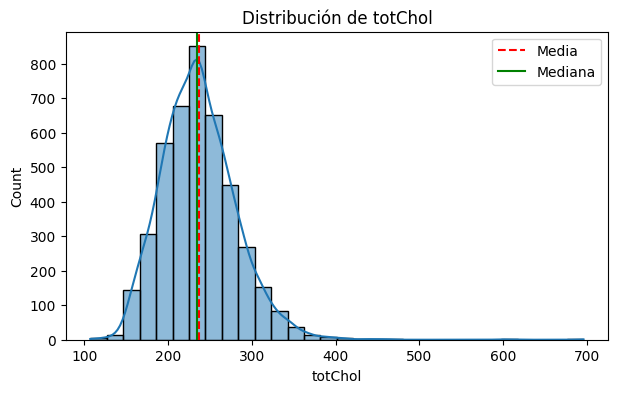

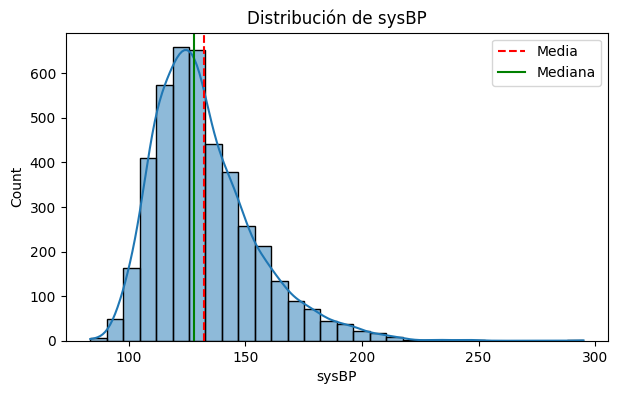

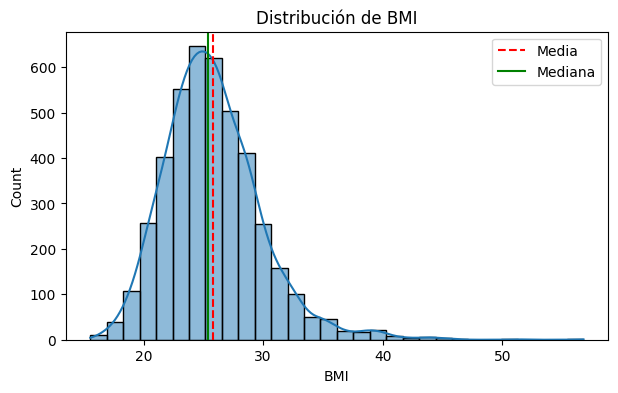

In [163]:
for col in df_filtrado.columns:
    plt.figure(figsize=(7,4))
    sns.histplot(data=df_filtrado, x=col, bins=30, kde=True)

    plt.axvline(df_filtrado[col].mean(), color='red', linestyle='--', label='Media')
    plt.axvline(df_filtrado[col].median(), color='green', linestyle='-', label='Mediana')

    plt.title(f'Distribución de {col}')
    plt.legend()
    plt.show()

In [164]:
# La variable 'totChol' presenta la mayor dispersión entre las variables analizadas,
# ya que posee el mayor coeficiente de variación (18,73%), indicando una mayor
# variabilidad respecto de su media. Además, el histograma muestra una distribución
# aproximadamente unimodal con una cola más extensa hacia la derecha, y un valor
# máximo considerablemente alejado de la media y la mediana, lo que sugiere la
# presencia de valores extremos que incrementan su dispersión.

3. Elimina los datos atípicos del dataset. Para las siguientes preguntas, considera el
dataset "limpio"


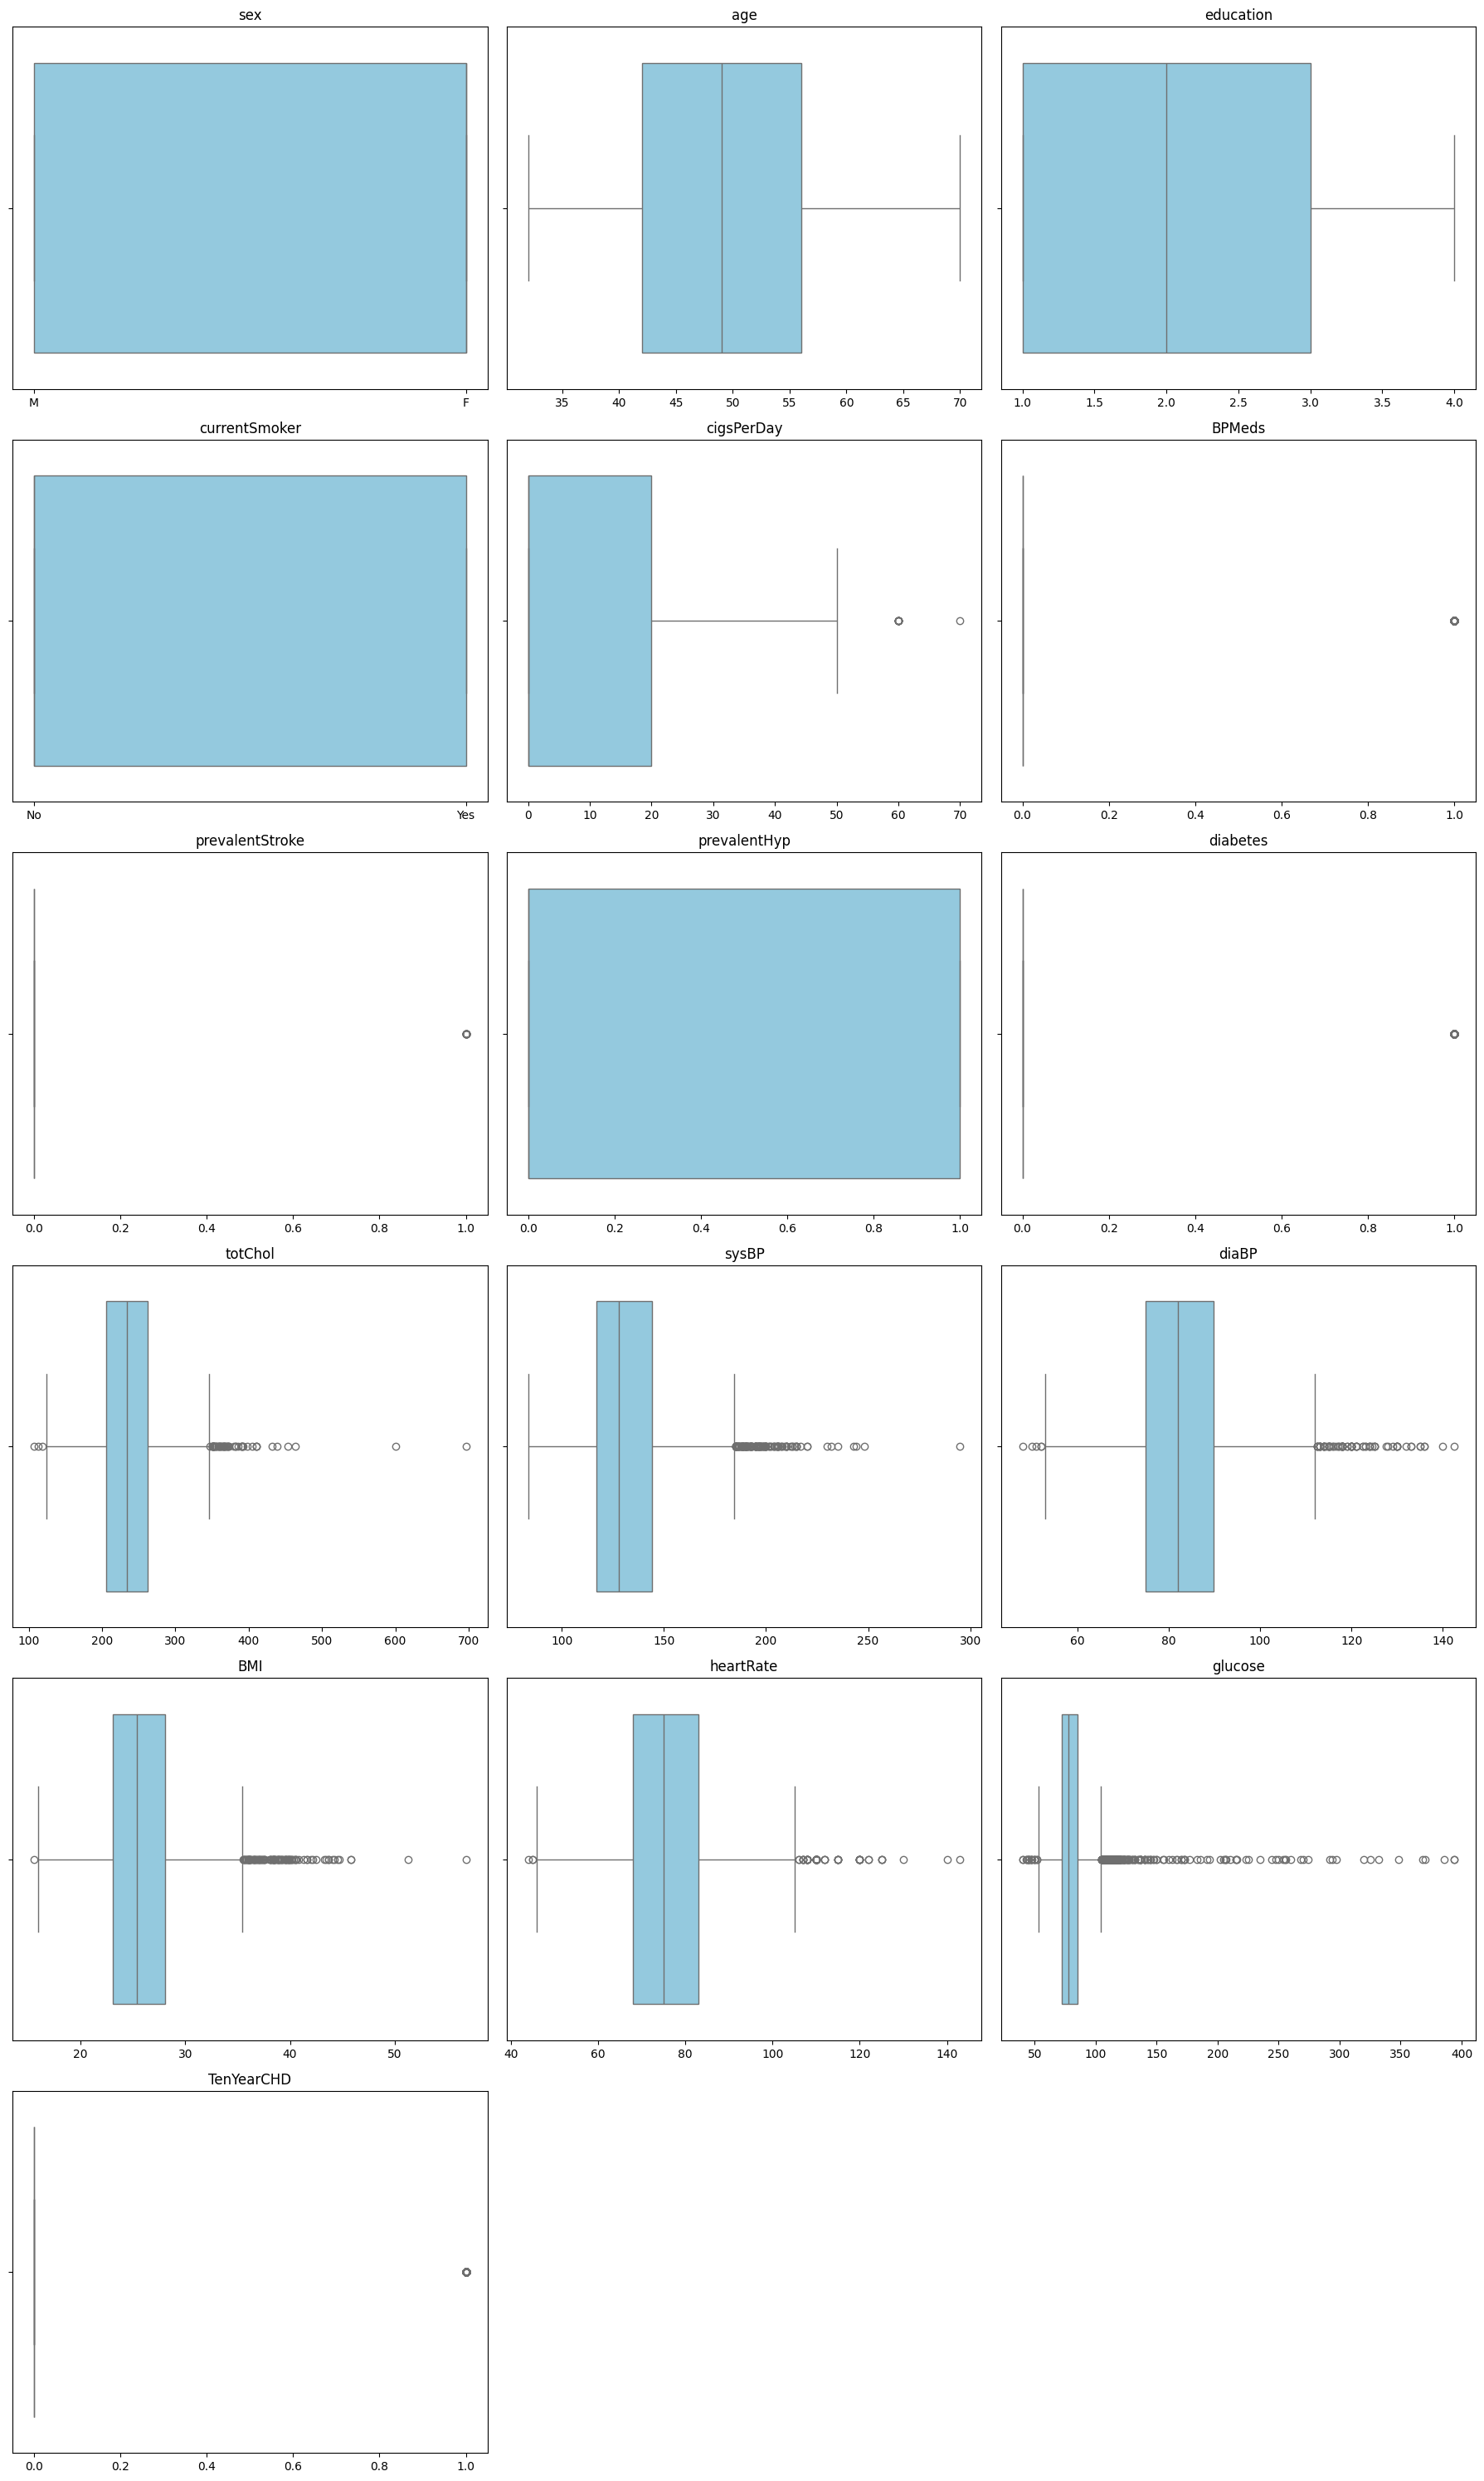

In [165]:
num_cols = 3
num_vars = len(df.columns)
num_rows = (num_vars + num_cols - 1) // num_cols  # calcular número de filas necesario

# Crear figura
plt.figure(figsize=(18, 5 * num_rows))

for i, col in enumerate(df.columns, 1):
    plt.subplot(num_rows, num_cols, i)
    sns.boxplot(x=df[col], color="skyblue")
    plt.title(col, fontsize=12)
    plt.xlabel("")

plt.tight_layout()
plt.show()

In [166]:
# La detección y eliminación de valores atípicos se realizará únicamente sobre las
# variables cuantitativas continuas ('totChol', 'sysBP', 'diaBP', 'BMI',
# 'heartRate' y 'glucose'). No se consideran las variables binarias o categóricas,
# ya que sus valores (por ejemplo, 0 y 1) representan categorías válidas y no
# corresponden a datos atípicos.

In [167]:
# Variables donde se eliminarán valores atípicos
variables_outliers = ['totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
df_sin_outliers = df

for col in variables_outliers:
    Q1 = df_sin_outliers[col].quantile(0.25)
    Q3 = df_sin_outliers[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    df_sin_outliers = df_sin_outliers[
        (df_sin_outliers[col] >= lim_inf) &
        (df_sin_outliers[col] <= lim_sup)]

In [168]:
# Siguiendo las instrucciones de la prueba, se eliminaron los valores atípicos de las
# variables cuantitativas continuas mediante el criterio del IQR. No obstante, en un
# contexto clínico, algunos de estos valores extremos podrían corresponder a pacientes
# con un mayor riesgo cardiovascular y, por tanto, contener información relevante para
# la predicción de enfermedades coronarias. Su eliminación podría reducir la capacidad
# del modelo para aprender estos casos.


4. ¿Qué variables cuantitativas presentan mayor correlación? Explica.


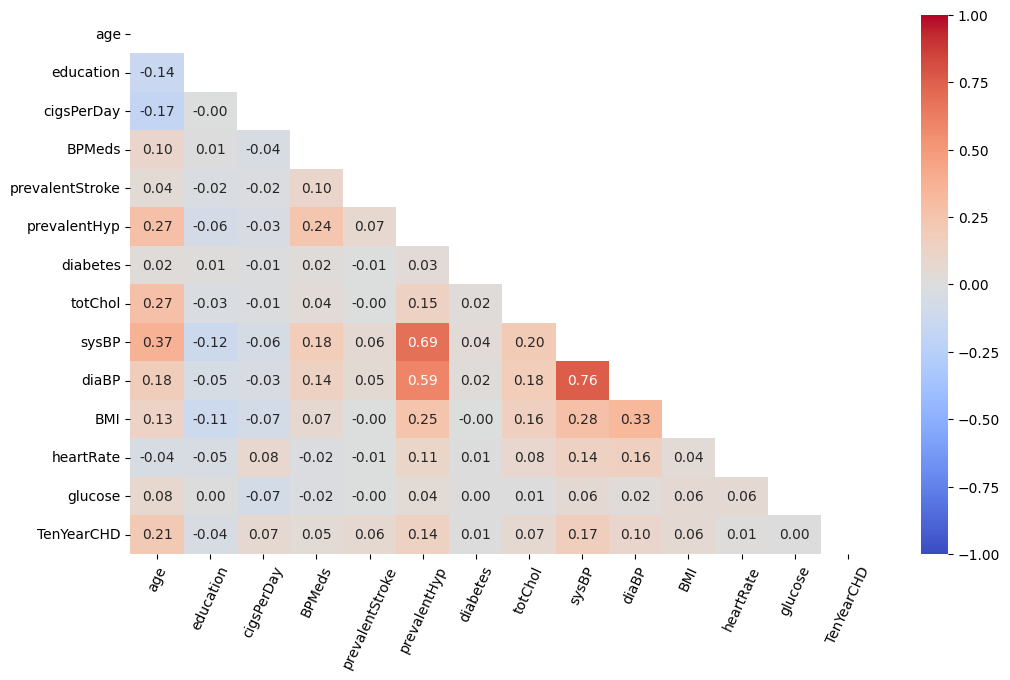

In [169]:
mask = np.triu(np.ones_like(df_sin_outliers.corr(numeric_only=True), dtype=bool))

plt.figure(figsize=(12,7))
sns.heatmap(df_sin_outliers.corr(numeric_only=True),vmin=-1,vmax=1,annot=True,cmap='coolwarm',fmt='.2f',mask=mask)
plt.xticks(rotation=65)
plt.show()

In [170]:
# Como era de esperar, las variables de presión arterial sistólica (sysBP) y diastólica (diaBP)
# presentan una alta correlación positiva (0.76), indicando una fuerte relación lineal entre
# ambas. Asimismo, estas variables muestran una correlación positiva cercana a 0.69 - 0.59 con 'prevalentHyp',
# lo que resulta consistente, dado que esta variable identifica a los pacientes con hipertensión.

5. Si de este dataset se escoge un paciente al azar, ¿cuál es la probabilidad de que sea
hombre, si se sabe que pertenece al mayor cuartil de la variable correspondiente al
índice de masa corporal?



In [171]:
Q3 = df_sin_outliers['BMI'].quantile(0.75)
condicion= df_sin_outliers[df_sin_outliers['BMI']>Q3]
probabilidad=(condicion['sex']=='M').mean()
print(f'La probabilidad de que al escoger un paciente al azar sea hombre y este en el mayor cuartil de BMI ({Q3:.2f}) es: {probabilidad:.2%}')

La probabilidad de que al escoger un paciente al azar sea hombre y este en el mayor cuartil de BMI (27.70) es: 53.19%


6. ¿Es razonable afirmar que, para una persona cualquiera (no necesariamente dentro
del dataset), su ritmo cardiaco promedio es 75? Explica y justifica

In [172]:

media_muestra=75
t_stat ,p_value=stats.ttest_1samp(df_sin_outliers['heartRate'],media_muestra,alternative='two-sided')
t_stat ,p_value


(np.float64(-1.8897448460137583), np.float64(0.05887150620363569))

In [173]:
# Se realizó una prueba t de una muestra para evaluar si la frecuencia cardíaca
# promedio de la población es igual a 75 latidos por minuto.
#
# H0: x = 75
# H1: x != 75
#
# Como el p-value (0.0589) es mayor que el nivel de significancia (α = 0.05),
# no existe evidencia estadística suficiente para rechazar la hipótesis nula.
# Por lo tanto, es razonable afirmar que la frecuencia cardíaca promedio de una
# persona puede ser de 75 latidos por minuto, ya que la muestra no aporta
# evidencia suficiente para sostener que sea diferente.

7. Ser hombre, ¿influye en el promedio de cigarrillos consumidos por día, dentro de los
pacientes fumadores? Explica.

In [174]:
fumadores = df_sin_outliers[df_sin_outliers['currentSmoker']== 'Yes']
hombres = fumadores[fumadores['sex'] == 'M']['cigsPerDay']
mujeres = fumadores[fumadores['sex'] == 'F']['cigsPerDay']

t_stat,p_value=stats.ttest_ind(hombres,mujeres, equal_var=False)
t_stat,p_value
print(f'estadístico t: {t_stat:.2f}')
print(f'p valor: {p_value}')
print(f'consumo promedio diario de cigarros por hombres: {hombres.mean():.2f}')
print(f'consumo promedio diario de cigarros por mujeres: {mujeres.mean():.2f}')

estadístico t: 16.35
p valor: 3.7413818420521045e-56
consumo promedio diario de cigarros por hombres: 21.91
consumo promedio diario de cigarros por mujeres: 14.14


In [175]:
# H0: promedio hombres = promedio mujeres
# H1: promedio hombres != promedio mujeres

# El valor p (3.74e-56) es considereblemente menor al nivel de confianza estandar (alpha:5%),
# Por lo que se rechaza la hipotesis nula, existe una diferencia en los promedios de consumo diario de cigarro según el sexo.
# Los hombres que fuman, en promedio consumen 7 cigarros mas al dia que las mujeres, por lo que,
# si el paciente es hombre si influye.

8. Construye un modelo de regresión lineal que permita relacionar 6 variables del
dataset con el índice de masa corporal. (Debes incluir al menos dos variables
cualitativas). Evalúa tu modelo y explica.


In [176]:
def regresion(dataframe, variables_independientes, variable_dependiente):

    # Variables independientes y dependiente
    X = dataframe[variables_independientes]
    y = dataframe[variable_dependiente]

    # Codificar variables cualitativas
    X = pd.get_dummies(X,columns=['sex', 'currentSmoker'],drop_first=True).astype(float)

    # Separar entrenamiento y prueba
    X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

    # Agregar constante
    X_train = sm.add_constant(X_train)
    X_test = sm.add_constant(X_test)

    # Modelo de Regresión Lineal
    model = sm.OLS(y_train, X_train).fit()
    summary = model.summary()

    # Predicciones sobre el conjunto de prueba
    predictions = model.predict(X_test)

    # Métricas
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, predictions)
    r_squared = r2_score(y_test, predictions)

    metrics_dict = {
        "Coeficiente de Determinación (R^2)": r_squared,
        "Error Cuadrático Medio (MSE)": mse,
        "Raíz de Error Cuadrático Medio (RMSE)": rmse,
        "Error Absoluto Medio (MAE)": mae
    }

    return [metrics_dict, X_test, y_test, predictions, summary]

In [177]:
variables = [
    'currentSmoker',
    'sex',
    'sysBP',
    'totChol',
    'heartRate',
    'education'
]

resultado = regresion(df_sin_outliers, variables, 'BMI')

metrics_dict = resultado[0]
summary = resultado[4]


In [178]:
for metric, value in metrics_dict.items():
  print(f"{metric}: {value:.2f}")

Coeficiente de Determinación (R^2): 0.14
Error Cuadrático Medio (MSE): 9.96
Raíz de Error Cuadrático Medio (RMSE): 3.16
Error Absoluto Medio (MAE): 2.47


In [179]:
print(summary)

                            OLS Regression Results                            
Dep. Variable:                    BMI   R-squared:                       0.148
Model:                            OLS   Adj. R-squared:                  0.146
Method:                 Least Squares   F-statistic:                     83.96
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           3.11e-97
Time:                        07:52:15   Log-Likelihood:                -7523.7
No. Observations:                2912   AIC:                         1.506e+04
Df Residuals:                    2905   BIC:                         1.510e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                17.5176      0.64

In [180]:
# El modelo presenta un R**2 de 0.14, por lo que las variables seleccionadas explican
# aproximadamente el 14% de la variabilidad del BMI. Esto indica
# un bajo poder explicativo, sugiriendo que existen otros factores relevantes no
# considerados en el modelo.
# Además, el MAE (2.47) y el RMSE (3.16) indican que las predicciones presentan un
# error promedio cercano a 2.5–3 unidades de BMI, por lo que el modelo ofrece una
# capacidad predictiva limitada.

9. Construye un modelo de regresión logística para predecir el riesgo de sufrir una
enfermedad coronaria en los próximos diez años, a partir de las variables descritas.
Verifica el balanceo de datos y evalúa tu modelo.


In [181]:
df_sin_outliers.head()

,sex,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,M,39,4.0,No,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,F,46,2.0,No,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,M,48,1.0,Yes,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,F,61,3.0,Yes,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,F,46,3.0,Yes,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


<Axes: xlabel='TenYearCHD', ylabel='count'>

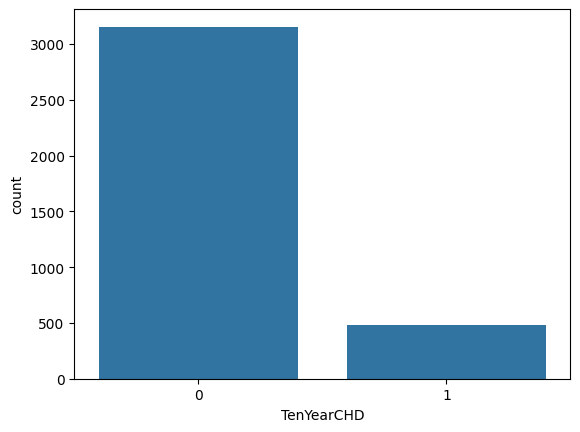

In [182]:
sns.countplot(x='TenYearCHD',data=df_sin_outliers) # Variable objetivo claramente desbalanceada

In [183]:
X = df_sin_outliers.drop(columns=['TenYearCHD'])
y = df_sin_outliers['TenYearCHD']

X = pd.get_dummies(X,columns=['sex', 'currentSmoker'],drop_first=True).astype(float)

In [184]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [185]:
scaler=StandardScaler()
X_train_scaled  = scaler.fit_transform(X_train)
X_test_scaled   = scaler.transform(X_test)

In [186]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)


In [187]:
log_model = LogisticRegression()
log_model.fit(X_train_smote,y_train_smote)

y_pred = log_model.predict(X_test_scaled)
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

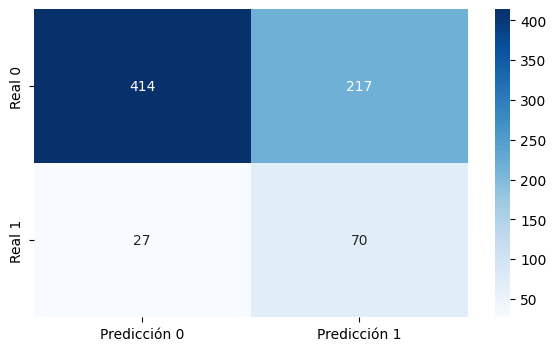

              precision    recall  f1-score   support

           0       0.94      0.66      0.77       631
           1       0.24      0.72      0.36        97

    accuracy                           0.66       728
   macro avg       0.59      0.69      0.57       728
weighted avg       0.85      0.66      0.72       728

AUC-ROC: 0.750


In [188]:
# matriz de confusión
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7,4))
sns.heatmap(conf_matrix, annot = True, fmt = '.0f', cmap = 'Blues', cbar = True,
            xticklabels = ['Predicción 0', 'Predicción 1'], yticklabels = ['Real 0', 'Real 1'])
plt.show()
print(classification_report(y_test, y_pred))
auc = roc_auc_score(y_test, y_prob)
print(f'AUC-ROC: {auc:.3f}')

In [189]:
# El modelo obtuvo un accuracy de 66% y un AUC-ROC de 0.75, lo que indica una
# capacidad discriminatoria aceptable para diferenciar pacientes con y sin riesgo
# de desarrollar enfermedad coronaria.

# Además, alcanzó un recall de 72% para la clase positiva, identificando la
# mayoría de los pacientes que desarrollarán la enfermedad. Sin embargo, la
# precisión fue de 24%, debido a la elevada cantidad de falsos positivos
# observados en la matriz de confusión.

# Este comportamiento es consistente con la aplicación de SMOTE sobre el conjunto
# de entrenamiento, técnica que mejora la detección de la clase minoritaria a
# costa de aumentar las falsas alarmas. En un contexto médico, este compromiso
# puede ser aceptable, ya que suele ser preferible detectar la mayor cantidad de
# pacientes en riesgo, aunque algunos pacientes sanos sean clasificados
# incorrectamente como positivos.

10. Separa los modelos de regresión anteriores en dos distintos, respectivamente,
considerando alguna variable categórica. Compara y conclu10. Separa los modelos de regresión anteriores en dos distintos, respectivamente,
considerando alguna variable categórica. Compara y concluye.
ye.


In [190]:
# Separación del df según sexo
df_hombres = df_sin_outliers[df_sin_outliers['sex'] == 'M']
df_mujeres = df_sin_outliers[df_sin_outliers['sex'] == 'F']

X_hombres= df_hombres.drop(columns=['TenYearCHD','sex'])
y_hombres=df_hombres['TenYearCHD']

X_mujeres= df_mujeres.drop(columns=['TenYearCHD','sex'])
y_mujeres=df_mujeres['TenYearCHD']

In [191]:
X_hombres= pd.get_dummies(X_hombres,columns=['currentSmoker'],drop_first=True).astype(float)

In [192]:
X_mujeres= pd.get_dummies(X_mujeres,columns=['currentSmoker'],drop_first=True).astype(float)

In [193]:
# Split
X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(X_hombres, y_hombres, test_size=0.2, random_state=42, stratify=y_hombres)
X_m_train, X_m_test, y_m_train, y_m_test = train_test_split(X_mujeres, y_mujeres, test_size=0.2, random_state=42, stratify=y_mujeres)

In [194]:
# SCALER
X_h_train_scaled  = scaler.fit_transform(X_h_train)
X_h_test_scaled   = scaler.transform(X_h_test)

X_m_train_scaled  = scaler.fit_transform(X_m_train)
X_m_test_scaled   = scaler.transform(X_m_test)

In [195]:
# SMOTE
X_h_train_smote, y_h_train_smote = smote.fit_resample(X_h_train_scaled, y_h_train)
X_m_train_smote, y_m_train_smote = smote.fit_resample(X_m_train_scaled, y_m_train)

In [196]:
# Modelo para hombres
log_model_h = LogisticRegression()
log_model_h.fit(X_h_train_smote, y_h_train_smote)

# Modelo para mujeres
log_model_m = LogisticRegression()
log_model_m.fit(X_m_train_smote, y_m_train_smote)

# Predicciones hombres
y_h_pred = log_model_h.predict(X_h_test_scaled)
y_h_prob = log_model_h.predict_proba(X_h_test_scaled)[:, 1]

# Predicciones mujeres
y_m_pred = log_model_m.predict(X_m_test_scaled)
y_m_prob = log_model_m.predict_proba(X_m_test_scaled)[:, 1]

In [197]:
def evaluar_modelo(y_test, y_pred, y_prob, titulo):

    # Matriz de confusión
    conf_matrix = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(7,4))
    sns.heatmap(
        conf_matrix,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Predicción 0', 'Predicción 1'],
        yticklabels=['Real 0', 'Real 1']
    )

    plt.title(f'Matriz de Confusión - {titulo}')
    plt.xlabel('Predicción')
    plt.ylabel('Valor Real')
    plt.show()

    # Reporte
    print(f'===== {titulo} =====')
    print(classification_report(y_test, y_pred))

    # AUC
    auc = roc_auc_score(y_test, y_prob)
    print(f'AUC-ROC: {auc:.3f}')

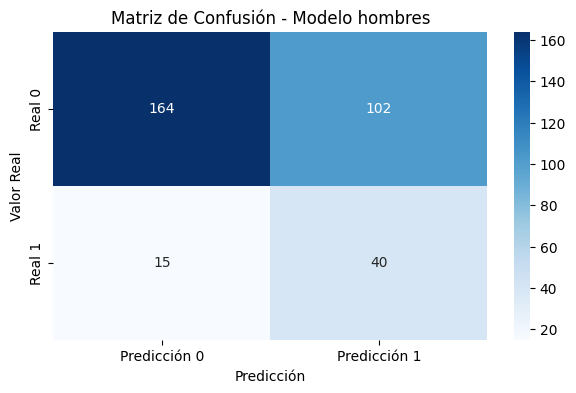

===== Modelo hombres =====
              precision    recall  f1-score   support

           0       0.92      0.62      0.74       266
           1       0.28      0.73      0.41        55

    accuracy                           0.64       321
   macro avg       0.60      0.67      0.57       321
weighted avg       0.81      0.64      0.68       321

AUC-ROC: 0.712


In [198]:
evaluar_modelo(y_h_test,y_h_pred,y_h_prob,titulo='Modelo hombres')

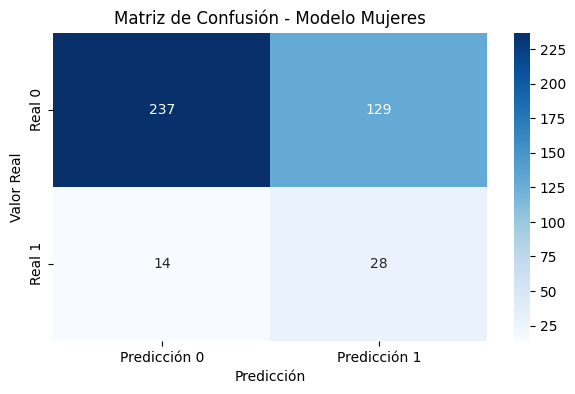

===== Modelo Mujeres =====
              precision    recall  f1-score   support

           0       0.94      0.65      0.77       366
           1       0.18      0.67      0.28        42

    accuracy                           0.65       408
   macro avg       0.56      0.66      0.52       408
weighted avg       0.87      0.65      0.72       408

AUC-ROC: 0.706


In [199]:
evaluar_modelo(y_m_test,y_m_pred,y_m_prob,titulo='Modelo Mujeres')

In [200]:
# Al separar el modelo por sexo se observan pequeñas diferencias en las métricas
# de desempeño; sin embargo, estas no representan una mejora significativa respecto
# al modelo general.

# El modelo para hombres obtuvo un recall y una precisión ligeramente superiores,
# mientras que el modelo para mujeres presentó un desempeño algo menor,
# especialmente en la precisión de la clase positiva.

# Además, el AUC-ROC disminuyó levemente en ambos modelos (≈0.71) respecto al
# modelo general (0.75), por lo que separar el conjunto de datos según el sexo
# no mejoró la capacidad predictiva del modelo.

# En consecuencia, no se observa evidencia de que construir modelos separados
# por sexo aporte un beneficio importante en la predicción de enfermedad
# coronaria para este conjunto de datos.